# Causality

In [71]:
from datascience import *
import numpy as np

%matplotlib inline
import matplotlib.pyplot as plots
plots.style.use('fivethirtyeight')

import warnings
warnings.simplefilter("ignore")

## Review: Comparing Two Samples

In [72]:
births = Table.read_table('baby.csv')

In [73]:
means = births.group('Maternal Smoker', np.average)
means

Maternal Smoker,Birth Weight average,Gestational Days average,Maternal Age average,Maternal Height average,Maternal Pregnancy Weight average
False,123.085,279.874,27.5441,64.014,129.48
True,113.819,277.898,26.7364,64.1046,126.919


In [74]:
observed_difference = means.column(1).item(1) - means.column(1).item(0)
observed_difference

-9.266142572024918

In [75]:
def difference_of_means(table, numeric_label, group_label):
    """
    Takes: name of table, column label of numerical variable,
    column label of group-label variable
    
    Returns: Difference of means of the two groups
    """
    
    #table with the two relevant columns
    reduced = table.select(numeric_label, group_label)  
    
    # table containing group means
    means_table = reduced.group(group_label, np.average)
    
    # array of group means
    means = means_table.column(1)
    
    return means.item(1) - means.item(0)

In [76]:
def one_simulated_difference(table, numeric_label, group_label):
    """
    Takes: name of table, column label of numerical variable,
    column label of group-label variable
    
    Returns: Difference of means of the two groups after shuffling labels
    """
    
    # array of shuffled labels
    shuffled_labels = table.sample(
        with_replacement = False).column(group_label)
    
    # table of numerical variable and shuffled labels
    shuffled_table = table.select(numeric_label).with_column(
        'Shuffled Label', shuffled_labels)
    
    return difference_of_means(
        shuffled_table, numeric_label, 'Shuffled Label')   

In [77]:
one_simulated_difference(births, 'Birth Weight', 'Maternal Smoker')

-0.3909837439249202

In [78]:
differences = make_array()

for i in np.arange(2000):
    new_difference = one_simulated_difference(births, 'Birth Weight', 'Maternal Smoker')
    differences = np.append(differences, new_difference)

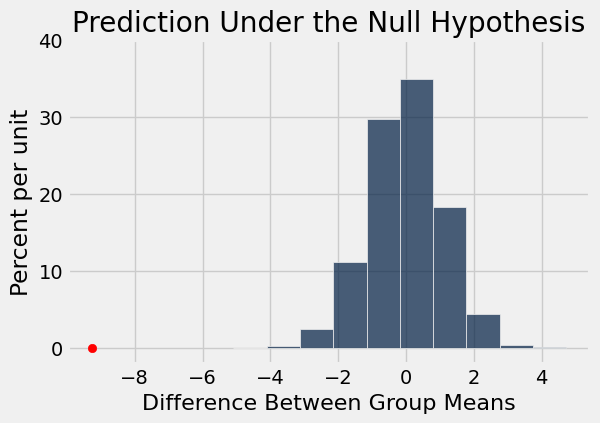

In [79]:
Table().with_column('Difference Between Group Means', differences).hist()
plots.ylim(-.02, .4)
plots.scatter(observed_difference, 0, color='red')

plots.title('Prediction Under the Null Hypothesis');

## Randomized Control Experiment

In [80]:
botox = Table.read_table('bta.csv')
botox.show()

Group,Result
Control,1
Control,1
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0
Control,0


**DISCUSS**: How would you use table methods to summarize the `botox` table?

In [81]:
botox.pivot('Result', 'Group')

Group,0.0,1.0
Control,14,2
Treatment,6,9


In [82]:
botox.group('Group', np.average)

Group,Result average
Control,0.125
Treatment,0.6


### Testing the Hypothesis

In [83]:
observed_diff = difference_of_means(botox, 'Result', 'Group')
observed_diff

0.475

In [84]:
one_simulated_difference(botox, 'Result', 'Group')

0.21666666666666667

In [85]:
simulated_diffs = make_array()

for i in np.arange(10000):
    sim_diff = one_simulated_difference(botox, 'Result', 'Group')
    simulated_diffs = np.append(simulated_diffs, sim_diff)

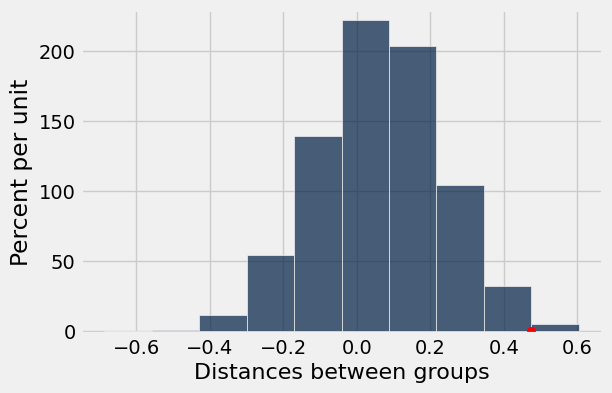

In [86]:
col_name = 'Distances between groups'
Table().with_column(col_name, simulated_diffs).hist(col_name)

plots.ylim(-.02, 2.3)
plots.scatter(observed_diff, 0, color='red');

In [87]:
# compute p-value
sum(simulated_diffs >= observed_diff) / len(simulated_diffs)

0.0066

**AT HOME**: Compare the null/alternative hypotheses in lecture vs. textbook (Section 12.2)